# Poverty-Aware Resource Allocation Model
## Interactive Exploration and Analysis

This notebook provides an interactive environment for exploring the poverty prediction model and resource allocation system.

### Project Overview
- **Objective**: Predict poverty levels across Indian districts and recommend optimal resource allocation
- **Data**: Synthetic district-level socio-economic indicators based on real patterns
- **Models**: Random Forest and XGBoost for poverty classification
- **Output**: Resource allocation recommendations with visualizations

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', 50)

# Set plotting style
plt.style.use('default')
sns.set_palette("husl")

print("✅ Libraries imported successfully!")
print(f"📊 Pandas version: {pd.__version__}")
print(f"🔢 NumPy version: {np.__version__}")

✅ Libraries imported successfully!
📊 Pandas version: 2.0.3
🔢 NumPy version: 1.24.3


## 1. Data Generation and Collection

Let's start by generating synthetic district data that mimics real Indian socio-economic patterns.

In [2]:
# Add project source to path
import sys
import os
sys.path.append(os.path.join(os.getcwd(), 'src'))

# Import project modules
from src.data_collection import IndianDistrictDataGenerator

# Generate district data
print("🏗️ Generating synthetic district data...")
generator = IndianDistrictDataGenerator(seed=42)
district_data = generator.generate_district_data(num_districts=50)  # Smaller dataset for notebook

print(f"\n📊 Generated data for {len(district_data)} districts")
print(f"📈 Features: {len(district_data.columns)}")
print(f"🎯 Poverty distribution: {district_data['Poverty_Level'].value_counts().to_dict()}")

🏗️ Generating synthetic district data...
Generating synthetic data for 50 Indian districts...
Generated data for 50 districts
Poverty distribution: {'Medium': 42, 'Low': 4, 'High': 4}

📊 Generated data for 50 districts
📈 Features: 17
🎯 Poverty distribution: {'Medium': 42, 'Low': 4, 'High': 4}


In [3]:
# Display first few rows
print("📋 Sample District Data:")
district_data.head()

📋 Sample District Data:


,District,State,Literacy_Rate,Female_Literacy_Rate,Employment_Rate,Clean_Water_Access,Electricity_Access,Healthcare_Index,Education_Index,Household_Size,Urban_Population_Pct,Toilet_Access,Bank_Account_Access,Internet_Access,Poverty_Score,Poverty_Level,Poverty_Class
0,Agra,Other,58.93,52.03,44.15,47.42,51.34,48.72,47.85,6.69,32.80,37.07,40.33,34.08,46.08,Medium,1
1,Lucknow,Uttar Pradesh,68.64,50.44,56.36,58.33,71.74,59.77,65.90,5.54,50.36,59.12,61.69,49.75,61.12,Medium,1
2,Kanpur,Other,52.55,45.78,38.93,37.39,40.96,36.77,41.15,7.47,20.40,37.91,51.52,26.58,38.67,Medium,1
3,Varanasi,Other,59.64,55.50,45.75,43.01,44.18,39.51,46.24,7.56,36.20,31.21,48.66,27.98,42.18,Medium,1
4,Allahabad,Other,54.12,37.96,43.36,40.75,44.57,39.43,40.68,6.99,18.37,37.37,40.64,21.19,40.91,Medium,1


In [4]:
# Basic data exploration
print("📊 Data Summary:")
print(f"Shape: {district_data.shape}")
print(f"Missing values: {district_data.isnull().sum().sum()}")

print("\n📈 Numerical Features Summary:")
numerical_cols = district_data.select_dtypes(include=[np.number]).columns
district_data[numerical_cols].describe()

📊 Data Summary:
Shape: (50, 17)
Missing values: 0

📈 Numerical Features Summary:


,Literacy_Rate,Female_Literacy_Rate,Employment_Rate,Clean_Water_Access,Electricity_Access,Healthcare_Index,Education_Index,Household_Size,Urban_Population_Pct,Toilet_Access,Bank_Account_Access,Internet_Access,Poverty_Score,Poverty_Class
count,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.00000,50.000000,50.000000,50.000000
mean,59.479000,47.768000,47.910800,47.248000,50.362200,45.061200,49.630000,7.016600,37.255600,41.686000,49.81020,31.557000,46.436600,1.000000
std,9.430205,7.466481,8.972348,13.335312,12.104037,12.116945,12.098395,0.732952,12.826314,12.967793,12.19108,12.590902,10.802195,0.404061
min,44.340000,36.920000,30.000000,22.360000,32.070000,27.010000,30.800000,4.730000,18.370000,21.900000,31.74000,11.650000,29.890000,0.000000
25%,54.160000,41.857500,42.820000,39.290000,44.190000,36.282500,42.195000,6.682500,28.012500,36.072500,41.95750,23.217500,39.847500,1.000000
50%,58.330000,45.075000,45.885000,45.090000,47.955000,41.970000,47.665000,7.085000,35.765000,38.905000,47.88000,28.955000,44.140000,1.000000
75%,62.255000,51.992500,51.555000,53.850000,55.612500,49.185000,51.565000,7.550000,43.712500,44.387500,53.26500,34.485000,48.962500,1.000000
max,89.780000,69.130000,80.000000,89.710000,91.330000,84.860000,88.700000,8.000000,69.450000,90.000000,88.64000,72.800000,84.480000,2.000000


## 2. Exploratory Data Analysis

Let's explore the relationships between different socio-economic indicators and poverty levels.

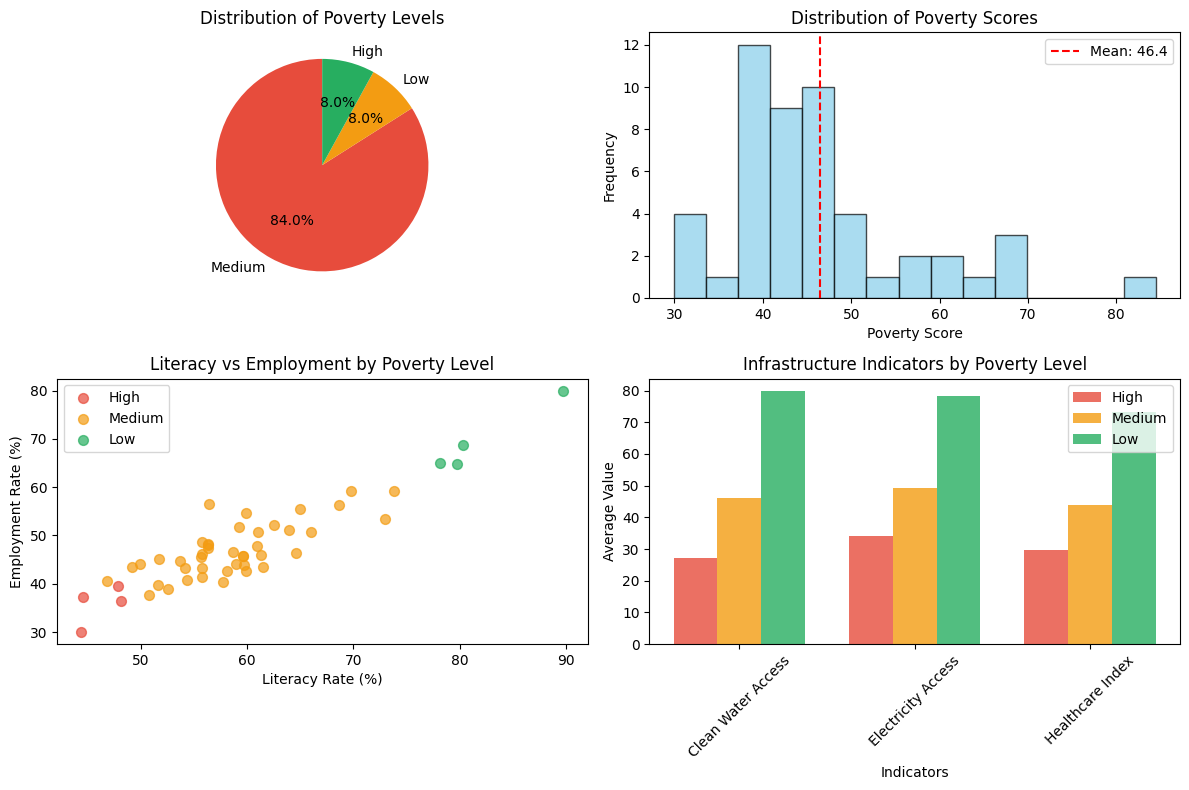

In [5]:
# Poverty level distribution
plt.figure(figsize=(12, 8))

# Subplot 1: Poverty distribution pie chart
plt.subplot(2, 2, 1)
poverty_counts = district_data['Poverty_Level'].value_counts()
colors = ['#e74c3c', '#f39c12', '#27ae60']  # Red, Orange, Green
plt.pie(poverty_counts.values, labels=poverty_counts.index, autopct='%1.1f%%', 
        colors=colors, startangle=90)
plt.title('Distribution of Poverty Levels')

# Subplot 2: Poverty score distribution
plt.subplot(2, 2, 2)
plt.hist(district_data['Poverty_Score'], bins=15, color='skyblue', alpha=0.7, edgecolor='black')
plt.axvline(district_data['Poverty_Score'].mean(), color='red', linestyle='--', 
           label=f'Mean: {district_data["Poverty_Score"].mean():.1f}')
plt.xlabel('Poverty Score')
plt.ylabel('Frequency')
plt.title('Distribution of Poverty Scores')
plt.legend()

# Subplot 3: Literacy vs Employment
plt.subplot(2, 2, 3)
for level, color in zip(['High', 'Medium', 'Low'], colors):
    data = district_data[district_data['Poverty_Level'] == level]
    plt.scatter(data['Literacy_Rate'], data['Employment_Rate'], 
               c=color, label=level, alpha=0.7, s=50)
plt.xlabel('Literacy Rate (%)')
plt.ylabel('Employment Rate (%)')
plt.title('Literacy vs Employment by Poverty Level')
plt.legend()

# Subplot 4: Infrastructure indicators
plt.subplot(2, 2, 4)
indicators = ['Clean_Water_Access', 'Electricity_Access', 'Healthcare_Index']
poverty_means = district_data.groupby('Poverty_Level')[indicators].mean()

x = np.arange(len(indicators))
width = 0.25

for i, (level, color) in enumerate(zip(['High', 'Medium', 'Low'], colors)):
    plt.bar(x + i * width, poverty_means.loc[level], width, label=level, color=color, alpha=0.8)

plt.xlabel('Indicators')
plt.ylabel('Average Value')
plt.title('Infrastructure Indicators by Poverty Level')
plt.xticks(x + width, [ind.replace('_', ' ') for ind in indicators], rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

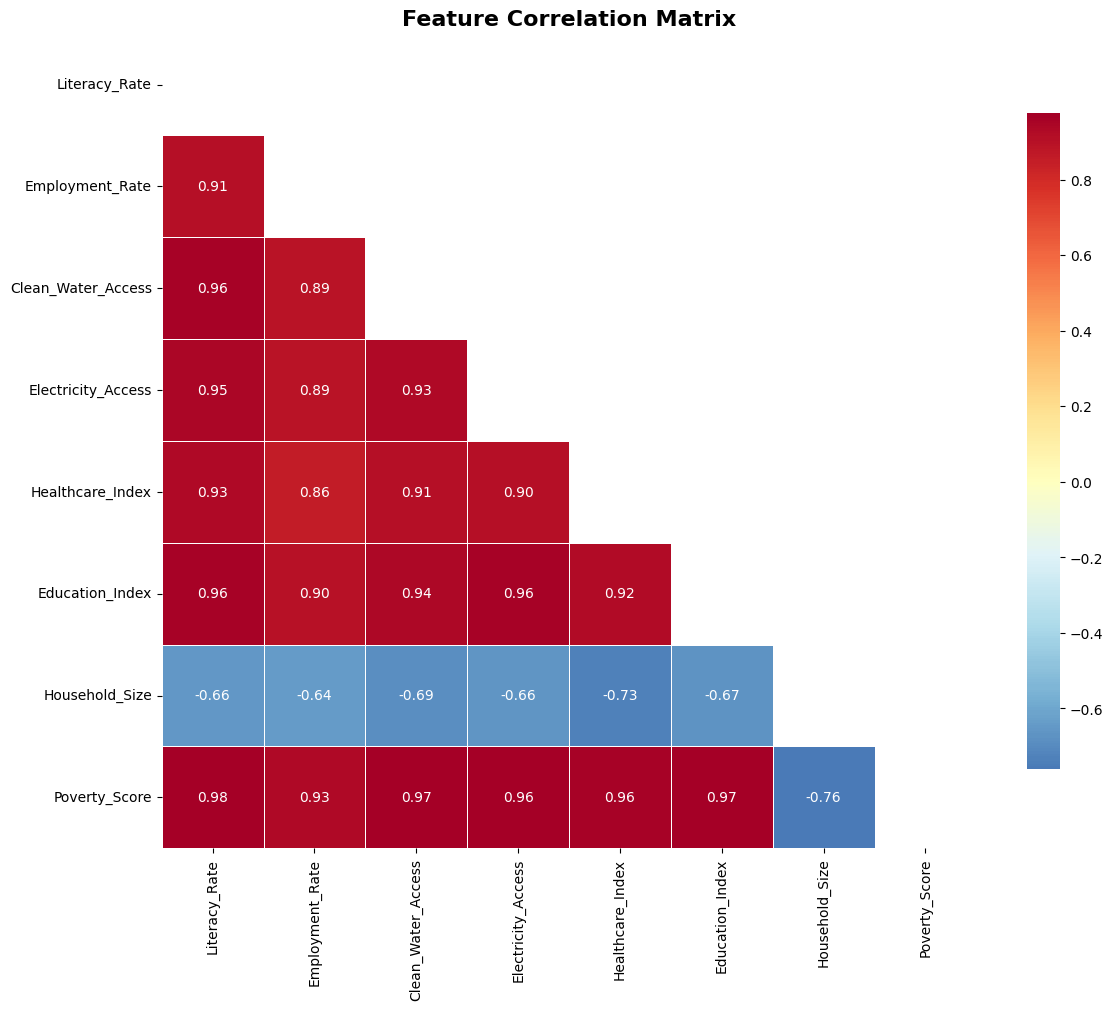


🎯 Strongest correlations with Poverty Score:
   Literacy_Rate: 0.976
   Education_Index: 0.975
   Clean_Water_Access: 0.967
   Electricity_Access: 0.964
   Healthcare_Index: 0.960
   Employment_Rate: 0.930
   Household_Size: -0.760


In [6]:
# Correlation analysis
plt.figure(figsize=(12, 10))

# Select numerical columns for correlation
corr_cols = ['Literacy_Rate', 'Employment_Rate', 'Clean_Water_Access', 
             'Electricity_Access', 'Healthcare_Index', 'Education_Index', 
             'Household_Size', 'Poverty_Score']

correlation_matrix = district_data[corr_cols].corr()

# Create heatmap
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap='RdYlBu_r', center=0,
           square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, fmt='.2f')

plt.title('Feature Correlation Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Show strongest correlations with poverty score
poverty_corr = district_data[corr_cols].corrwith(district_data['Poverty_Score']).sort_values(ascending=False)
print("\n🎯 Strongest correlations with Poverty Score:")
for feature, corr in poverty_corr.items():
    if feature != 'Poverty_Score':
        print(f"   {feature}: {corr:.3f}")

## 3. Data Preprocessing and Feature Engineering

Now let's preprocess the data and create additional features that might improve model performance.

In [7]:
# Import preprocessing module
from src.data_preprocessing import PovertyDataPreprocessor

# Initialize preprocessor
preprocessor = PovertyDataPreprocessor()

# Clean and enhance data
print("🧹 Cleaning data...")
clean_data = preprocessor.clean_data(district_data)

print("\n🔧 Engineering features...")
enhanced_data = preprocessor.feature_engineering(clean_data)

print(f"\n📊 Enhanced dataset shape: {enhanced_data.shape}")
print(f"🆕 New features created: {enhanced_data.shape[1] - district_data.shape[1]}")

# Show new features
new_features = [col for col in enhanced_data.columns if col not in district_data.columns]
print(f"\n🎯 New features: {new_features}")

🧹 Cleaning data...

=== Data Cleaning ===
Handling missing values...

Handling outliers...
  Capped 4 outliers in Literacy_Rate
  Capped 1 outliers in Female_Literacy_Rate
  Capped 4 outliers in Employment_Rate
  Capped 3 outliers in Clean_Water_Access
  Capped 3 outliers in Electricity_Access
  Capped 3 outliers in Healthcare_Index
  Capped 7 outliers in Education_Index
  Capped 1 outliers in Household_Size
  Capped 2 outliers in Urban_Population_Pct
  Capped 9 outliers in Toilet_Access
  Capped 4 outliers in Bank_Account_Access
  Capped 4 outliers in Internet_Access
  Capped 5 outliers in Poverty_Score

Validating data ranges...
Data cleaning completed. Shape: (50, 17)

🔧 Engineering features...

=== Feature Engineering ===
Created feature: Literacy_Gap
Created feature: Infrastructure_Score
Created feature: Development_Index
Created feature: Digital_Access_Score
Created features: Rural_Population_Pct, Urban_Rural_Ratio
Created feature: Household_Efficiency
Created feature: Poverty_Ri

In [8]:
# Prepare data for machine learning
print("⚙️ Preparing data for machine learning...")
X_train, X_test, y_train, y_test = preprocessor.prepare_features_for_ml(enhanced_data)

print(f"\n📈 Training set: {X_train.shape}")
print(f"📉 Test set: {X_test.shape}")
print(f"🎯 Target distribution in training:")
print(y_train.value_counts().to_dict())

# Display feature importance based on correlation
print("\n🔍 Feature importance (correlation with target):")
feature_corr = X_train.corrwith(y_train).abs().sort_values(ascending=False)
for i, (feature, corr) in enumerate(feature_corr.head(10).items()):
    print(f"{i+1:2d}. {feature}: {corr:.3f}")

⚙️ Preparing data for machine learning...

=== Preparing Features for ML ===
Features selected: 20
Features: ['Literacy_Rate', 'Female_Literacy_Rate', 'Employment_Rate', 'Clean_Water_Access', 'Electricity_Access', 'Healthcare_Index', 'Education_Index', 'Household_Size', 'Urban_Population_Pct', 'Toilet_Access', 'Bank_Account_Access', 'Internet_Access', 'Literacy_Gap', 'Infrastructure_Score', 'Development_Index', 'Digital_Access_Score', 'Rural_Population_Pct', 'Urban_Rural_Ratio', 'Household_Efficiency', 'Poverty_Risk_Score']
Training set: (40, 20)
Test set: (10, 20)
Feature scaling completed

📈 Training set: (40, 20)
📉 Test set: (10, 20)
🎯 Target distribution in training:
{1: 34, 0: 3, 2: 3}

🔍 Feature importance (correlation with target):
 1. Poverty_Risk_Score: 0.198
 2. Household_Size: 0.171
 3. Household_Efficiency: 0.144
 4. Employment_Rate: 0.108
 5. Female_Literacy_Rate: 0.074
 6. Internet_Access: 0.065
 7. Literacy_Gap: 0.060
 8. Development_Index: 0.036
 9. Literacy_Rate: 0.034

## 4. Model Training and Evaluation

Let's train machine learning models to predict poverty levels.

In [9]:
# Import required ML libraries (if available)
try:
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
    from sklearn.model_selection import cross_val_score
    
    # Train Random Forest model
    print("🌲 Training Random Forest model...")
    rf_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
    
    rf_model.fit(X_train, y_train)
    
    # Make predictions
    y_pred = rf_model.predict(X_test)
    y_pred_proba = rf_model.predict_proba(X_test)
    
    # Evaluate model
    accuracy = accuracy_score(y_test, y_pred)
    cv_scores = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='accuracy')
    
    print(f"\n📊 Model Performance:")
    print(f"   Test Accuracy: {accuracy:.4f}")
    print(f"   CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")
    
    print(f"\n📋 Classification Report:")
    print(classification_report(y_test, y_pred, 
                              target_names=['High Poverty', 'Medium Poverty', 'Low Poverty']))
    
    sklearn_available = True
    
except ImportError:
    print("⚠️ Scikit-learn not available. Skipping model training.")
    print("💡 Install with: pip install scikit-learn")
    sklearn_available = False

🌲 Training Random Forest model...

📊 Model Performance:
   Test Accuracy: 1.0000
   CV Accuracy: 0.9500 (+/- 0.1225)

📋 Classification Report:
                precision    recall  f1-score   support

  High Poverty       1.00      1.00      1.00         1
Medium Poverty       1.00      1.00      1.00         8
   Low Poverty       1.00      1.00      1.00         1

      accuracy                           1.00        10
     macro avg       1.00      1.00      1.00        10
  weighted avg       1.00      1.00      1.00        10


📊 Model Performance:
   Test Accuracy: 1.0000
   CV Accuracy: 0.9500 (+/- 0.1225)

📋 Classification Report:
                precision    recall  f1-score   support

  High Poverty       1.00      1.00      1.00         1
Medium Poverty       1.00      1.00      1.00         8
   Low Poverty       1.00      1.00      1.00         1

      accuracy                           1.00        10
     macro avg       1.00      1.00      1.00        10
  weighted avg 

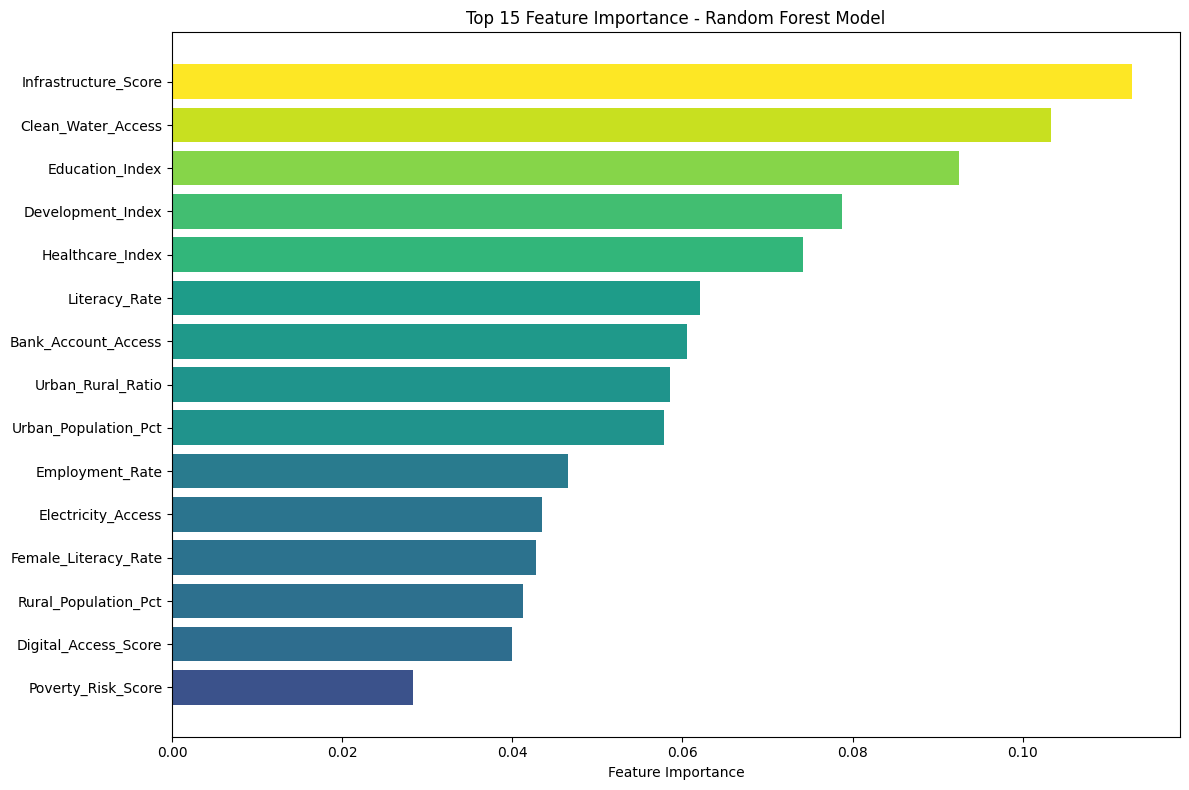


🏆 Top 10 Most Important Features:
 1. Infrastructure_Score: 0.1129
 2. Clean_Water_Access: 0.1033
 3. Education_Index: 0.0926
 4. Development_Index: 0.0788
 5. Healthcare_Index: 0.0742
 6. Literacy_Rate: 0.0621
 7. Bank_Account_Access: 0.0605
 8. Urban_Rural_Ratio: 0.0585
 9. Urban_Population_Pct: 0.0578
10. Employment_Rate: 0.0465


In [10]:
# Feature importance analysis (if sklearn is available)
if sklearn_available:
    # Get feature importance
    feature_importance = pd.DataFrame({
        'feature': X_train.columns,
        'importance': rf_model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    # Plot feature importance
    plt.figure(figsize=(12, 8))
    
    # Top 15 features
    top_features = feature_importance.head(15)
    
    plt.barh(range(len(top_features)), top_features['importance'])
    plt.yticks(range(len(top_features)), top_features['feature'])
    plt.xlabel('Feature Importance')
    plt.title('Top 15 Feature Importance - Random Forest Model')
    plt.gca().invert_yaxis()
    
    # Color bars by importance
    colors = plt.cm.viridis(top_features['importance'] / top_features['importance'].max())
    bars = plt.barh(range(len(top_features)), top_features['importance'], color=colors)
    
    plt.tight_layout()
    plt.show()
    
    print("\n🏆 Top 10 Most Important Features:")
    for i, (_, row) in enumerate(feature_importance.head(10).iterrows()):
        print(f"{i+1:2d}. {row['feature']}: {row['importance']:.4f}")

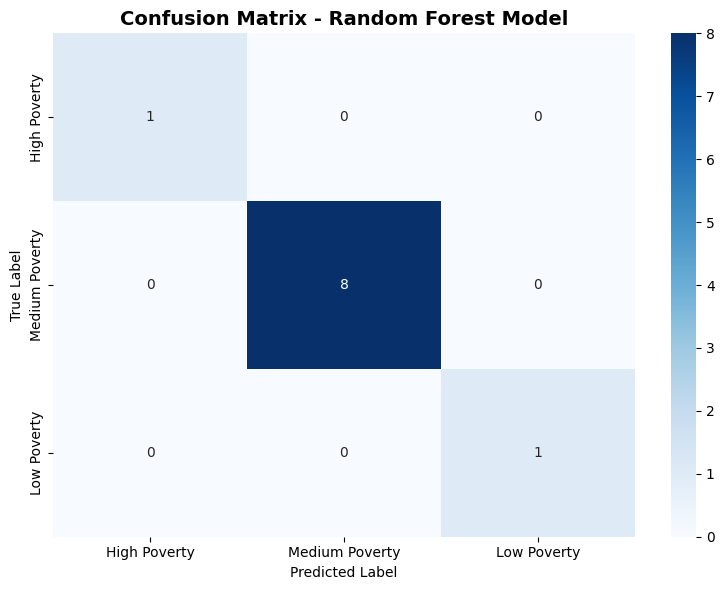

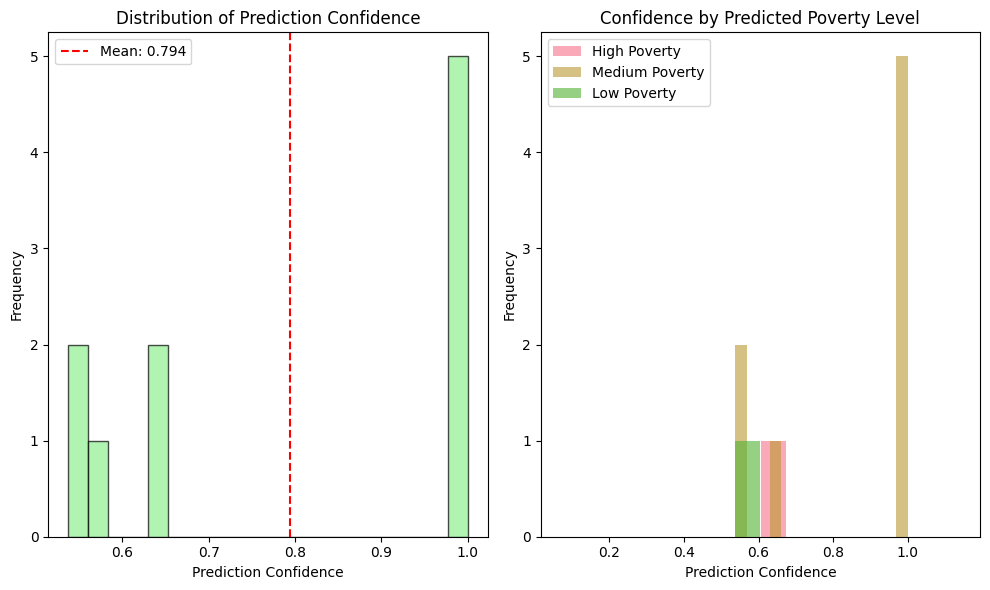


📊 Prediction Confidence Statistics:
   Mean confidence: 0.794
   Median confidence: 0.821
   Min confidence: 0.537
   Max confidence: 1.000


In [11]:
# Confusion matrix visualization (if sklearn is available)
if sklearn_available:
    plt.figure(figsize=(8, 6))
    
    conf_matrix = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
               xticklabels=['High Poverty', 'Medium Poverty', 'Low Poverty'],
               yticklabels=['High Poverty', 'Medium Poverty', 'Low Poverty'])
    
    plt.title('Confusion Matrix - Random Forest Model', fontsize=14, fontweight='bold')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    
    plt.tight_layout()
    plt.show()
    
    # Prediction confidence analysis
    confidence_scores = np.max(y_pred_proba, axis=1)
    
    plt.figure(figsize=(10, 6))
    
    plt.subplot(1, 2, 1)
    plt.hist(confidence_scores, bins=20, color='lightgreen', alpha=0.7, edgecolor='black')
    plt.axvline(confidence_scores.mean(), color='red', linestyle='--', 
               label=f'Mean: {confidence_scores.mean():.3f}')
    plt.xlabel('Prediction Confidence')
    plt.ylabel('Frequency')
    plt.title('Distribution of Prediction Confidence')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    # Confidence by predicted class
    for class_idx, class_name in enumerate(['High', 'Medium', 'Low']):
        class_confidence = confidence_scores[y_pred == class_idx]
        plt.hist(class_confidence, alpha=0.6, label=f'{class_name} Poverty', bins=15)
    
    plt.xlabel('Prediction Confidence')
    plt.ylabel('Frequency')
    plt.title('Confidence by Predicted Poverty Level')
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n📊 Prediction Confidence Statistics:")
    print(f"   Mean confidence: {confidence_scores.mean():.3f}")
    print(f"   Median confidence: {np.median(confidence_scores):.3f}")
    print(f"   Min confidence: {confidence_scores.min():.3f}")
    print(f"   Max confidence: {confidence_scores.max():.3f}")

## 5. Resource Allocation Analysis

Now let's calculate resource allocation based on our poverty predictions.

In [13]:
# Create predictions for all districts (if model is available)
if sklearn_available:
    # Predict for all districts
    all_X = pd.concat([X_train, X_test], ignore_index=True)
    all_predictions = rf_model.predict(all_X)
    all_prediction_probs = rf_model.predict_proba(all_X)
    
    # Create results dataframe
    results_df = enhanced_data[['District', 'State']].copy()
    results_df['Predicted_Class'] = all_predictions
    results_df['Predicted_Level'] = [['High', 'Medium', 'Low'][pred] for pred in all_predictions]
    results_df['Confidence'] = np.max(all_prediction_probs, axis=1)
    
else:
    # Use original poverty levels for demonstration
    results_df = enhanced_data[['District', 'State', 'Poverty_Level']].copy()
    results_df['Predicted_Level'] = results_df['Poverty_Level']
    results_df['Confidence'] = np.random.uniform(0.6, 0.95, len(results_df))  # Simulated confidence

print(f"📊 Prediction Results for {len(results_df)} districts:")
print(results_df['Predicted_Level'].value_counts())

📊 Prediction Results for 50 districts:
Predicted_Level
Medium    42
High       4
Low        4
Name: count, dtype: int64


In [14]:
# Calculate resource allocation
from src.resource_allocation import ResourceAllocationEngine

# Initialize allocation engine
allocator = ResourceAllocationEngine()

# Set budget
total_budget = 2000000000  # 2 billion rupees

print(f"💰 Calculating resource allocation for budget: ₹{total_budget:,.0f}")

# Prepare data for allocation (rename column to match expected format)
allocation_input = results_df.copy()
if 'Predicted_Class' in allocation_input.columns:
    # Map predicted levels to classes
    level_to_class = {'High': 0, 'Medium': 1, 'Low': 2}
    allocation_input['Poverty_Class'] = allocation_input['Predicted_Level'].map(level_to_class)
else:
    allocation_input['Poverty_Class'] = allocation_input['Predicted_Level'].map({'High': 0, 'Medium': 1, 'Low': 2})

# Calculate basic allocation
allocation_results = allocator.calculate_basic_allocation(allocation_input, total_budget)

print(f"\n📈 Allocation Summary:")
summary = allocator.generate_allocation_summary()
print(f"   Total districts: {summary['total_districts']}")
print(f"   Average allocation: ₹{summary['average_allocation']:,.0f}")
print(f"   Median allocation: ₹{summary['median_allocation']:,.0f}")

print(f"\n🎯 Allocation by poverty level:")
for level, data in summary['allocation_by_poverty_level'].items():
    print(f"   {level}: {data['districts']} districts, ₹{data['total_allocation']:,.0f} ({data['percentage_of_budget']:.1f}%)")

💰 Calculating resource allocation for budget: ₹2,000,000,000
=== Calculating Basic Resource Allocation ===
District distribution: {'Medium': 42, 'High': 4, 'Low': 4}
High Poverty: 4 districts, ₹1,000,000,000 total, ₹250,000,000 per district
Medium Poverty: 42 districts, ₹600,000,000 total, ₹14,285,714 per district
Low Poverty: 4 districts, ₹400,000,000 total, ₹100,000,000 per district

Total Budget: ₹2,000,000,000
Total Allocated: ₹2,000,000,000
Allocation Coverage: 100.0%

📈 Allocation Summary:
   Total districts: 50
   Average allocation: ₹40,000,000
   Median allocation: ₹14,285,714

🎯 Allocation by poverty level:
   High: 4 districts, ₹1,000,000,000 (50.0%)
   Medium: 42 districts, ₹600,000,000 (30.0%)
   Low: 4 districts, ₹400,000,000 (20.0%)


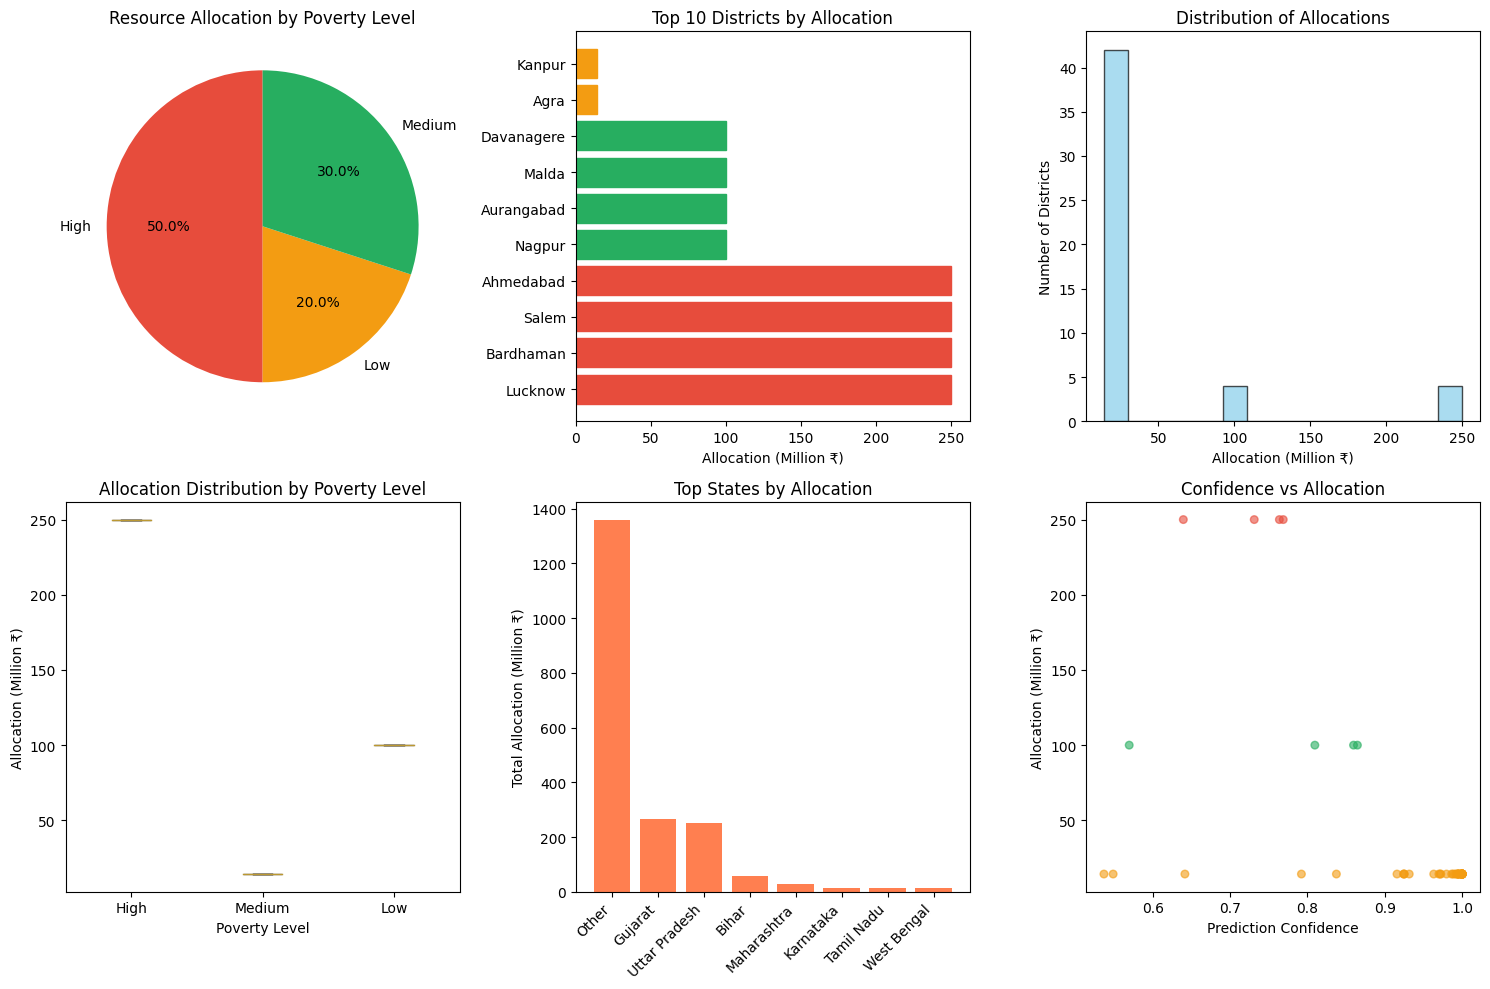

In [15]:
# Visualize resource allocation
plt.figure(figsize=(15, 10))

# Allocation by poverty level (pie chart)
plt.subplot(2, 3, 1)
poverty_allocation = allocation_results.groupby('Poverty_Level')['Allocated_Amount'].sum()
colors = ['#e74c3c', '#f39c12', '#27ae60']  # Red, Orange, Green
plt.pie(poverty_allocation.values, labels=poverty_allocation.index, autopct='%1.1f%%',
        colors=colors, startangle=90)
plt.title('Resource Allocation by Poverty Level')

# Top 10 districts by allocation
plt.subplot(2, 3, 2)
top_districts = allocation_results.nlargest(10, 'Allocated_Amount')
bars = plt.barh(range(len(top_districts)), top_districts['Allocated_Amount'] / 1e6)
plt.yticks(range(len(top_districts)), top_districts['District'])
plt.xlabel('Allocation (Million ₹)')
plt.title('Top 10 Districts by Allocation')

# Color bars by poverty level
color_map = {'High': '#e74c3c', 'Medium': '#f39c12', 'Low': '#27ae60'}
for bar, poverty_level in zip(bars, top_districts['Poverty_Level']):
    bar.set_color(color_map[poverty_level])

# Allocation distribution
plt.subplot(2, 3, 3)
plt.hist(allocation_results['Allocated_Amount'] / 1e6, bins=15, 
         color='skyblue', alpha=0.7, edgecolor='black')
plt.xlabel('Allocation (Million ₹)')
plt.ylabel('Number of Districts')
plt.title('Distribution of Allocations')

# Box plot by poverty level
plt.subplot(2, 3, 4)
box_data = [allocation_results[allocation_results['Poverty_Level'] == level]['Allocated_Amount'] / 1e6 
           for level in ['High', 'Medium', 'Low']]
box_plot = plt.boxplot(box_data, labels=['High', 'Medium', 'Low'], patch_artist=True)

# Color the boxes
for patch, color in zip(box_plot['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

plt.ylabel('Allocation (Million ₹)')
plt.xlabel('Poverty Level')
plt.title('Allocation Distribution by Poverty Level')

# State-wise allocation (if state data available)
if 'State' in allocation_results.columns:
    plt.subplot(2, 3, 5)
    state_allocation = allocation_results.groupby('State')['Allocated_Amount'].sum().sort_values(ascending=False)
    # Show top 8 states
    top_states = state_allocation.head(8)
    plt.bar(range(len(top_states)), top_states.values / 1e6, color='coral')
    plt.xticks(range(len(top_states)), top_states.index, rotation=45, ha='right')
    plt.ylabel('Total Allocation (Million ₹)')
    plt.title('Top States by Allocation')

# Efficiency metrics
plt.subplot(2, 3, 6)
if 'Confidence' in allocation_results.columns:
    plt.scatter(allocation_results['Confidence'], allocation_results['Allocated_Amount'] / 1e6,
               c=[color_map[level] for level in allocation_results['Poverty_Level']], 
               alpha=0.6, s=30)
    plt.xlabel('Prediction Confidence')
    plt.ylabel('Allocation (Million ₹)')
    plt.title('Confidence vs Allocation')
else:
    # Alternative plot if confidence not available
    avg_by_level = allocation_results.groupby('Poverty_Level')['Allocated_Amount'].mean()
    plt.bar(avg_by_level.index, avg_by_level.values / 1e6, color=colors)
    plt.ylabel('Average Allocation (Million ₹)')
    plt.title('Average Allocation by Level')

plt.tight_layout()
plt.show()

In [18]:
# Detailed allocation results table
print("📊 Detailed Allocation Results (Top 15 Districts):")

# Get top 15 districts by allocation
top_15_results = allocation_results.nlargest(15, 'Allocated_Amount')

# Create simplified display table
display_data = []
for _, row in top_15_results.iterrows():
    allocation_formatted = f"₹{row['Allocated_Amount']/1e6:.2f}M"
    share_formatted = f"{row['District_Share']:.2f}%"
    
    if 'Confidence' in row and not pd.isna(row['Confidence']):
        confidence_formatted = f"{row['Confidence']:.1%}"
        display_data.append([
            row['District'], row['State'], row['Poverty_Level'], 
            confidence_formatted, allocation_formatted, share_formatted
        ])
    else:
        display_data.append([
            row['District'], row['State'], row['Poverty_Level'], 
            allocation_formatted, share_formatted
        ])

# Create DataFrame with proper column names
if 'Confidence' in allocation_results.columns:
    columns = ['District', 'State', 'Poverty Level', 'Confidence', 'Allocation', 'Share (%)']
else:
    columns = ['District', 'State', 'Poverty Level', 'Allocation', 'Share (%)']

display_df = pd.DataFrame(display_data, columns=columns)
print(display_df.to_string(index=False))

📊 Detailed Allocation Results (Top 15 Districts):
  District         State Poverty Level Confidence Allocation Share (%)
   Lucknow Uttar Pradesh          High      76.4%   ₹250.00M    12.50%
 Bardhaman         Other          High      76.9%   ₹250.00M    12.50%
     Salem         Other          High      73.1%   ₹250.00M    12.50%
 Ahmedabad       Gujarat          High      64.0%   ₹250.00M    12.50%
    Nagpur         Other           Low      81.0%   ₹100.00M     5.00%
Aurangabad         Other           Low      86.5%   ₹100.00M     5.00%
     Malda         Other           Low      86.0%   ₹100.00M     5.00%
Davanagere         Other           Low      57.0%   ₹100.00M     5.00%
      Agra         Other        Medium      92.5%    ₹14.29M     0.71%
    Kanpur         Other        Medium      92.5%    ₹14.29M     0.71%
  Varanasi         Other        Medium      93.2%    ₹14.29M     0.71%
 Allahabad         Other        Medium     100.0%    ₹14.29M     0.71%
    Meerut         Other   

## 6. Interactive Analysis and What-If Scenarios

Let's explore different allocation strategies and scenarios.

In [19]:
# Compare different allocation strategies
strategies = {
    'Current (50-30-20)': {'High': 0.50, 'Medium': 0.30, 'Low': 0.20},
    'High Focus (60-25-15)': {'High': 0.60, 'Medium': 0.25, 'Low': 0.15},
    'Balanced (40-35-25)': {'High': 0.40, 'Medium': 0.35, 'Low': 0.25},
    'Equal (33-33-34)': {'High': 0.33, 'Medium': 0.33, 'Low': 0.34}
}

print("🔄 Comparing Different Allocation Strategies:")
print("="*60)

strategy_results = {}

for strategy_name, strategy in strategies.items():
    # Set new strategy
    allocator.set_allocation_strategy(strategy)
    
    # Calculate allocation
    strategy_allocation = allocator.calculate_basic_allocation(allocation_input, total_budget)
    
    # Store results
    strategy_results[strategy_name] = {
        'allocation_df': strategy_allocation,
        'summary': allocator.generate_allocation_summary()
    }
    
    print(f"\n📊 {strategy_name}:")
    summary = strategy_results[strategy_name]['summary']
    for level, data in summary['allocation_by_poverty_level'].items():
        avg_allocation = data['total_allocation'] / data['districts']
        print(f"   {level}: ₹{avg_allocation:,.0f} per district ({data['percentage_of_budget']:.1f}% of budget)")

🔄 Comparing Different Allocation Strategies:
Updated allocation strategy: {'High': 0.5, 'Medium': 0.3, 'Low': 0.2}
=== Calculating Basic Resource Allocation ===
District distribution: {'Medium': 42, 'High': 4, 'Low': 4}
High Poverty: 4 districts, ₹1,000,000,000 total, ₹250,000,000 per district
Medium Poverty: 42 districts, ₹600,000,000 total, ₹14,285,714 per district
Low Poverty: 4 districts, ₹400,000,000 total, ₹100,000,000 per district

Total Budget: ₹2,000,000,000
Total Allocated: ₹2,000,000,000
Allocation Coverage: 100.0%

📊 Current (50-30-20):
   High: ₹250,000,000 per district (50.0% of budget)
   Medium: ₹14,285,714 per district (30.0% of budget)
   Low: ₹100,000,000 per district (20.0% of budget)
Updated allocation strategy: {'High': 0.6, 'Medium': 0.25, 'Low': 0.15}
=== Calculating Basic Resource Allocation ===
District distribution: {'Medium': 42, 'High': 4, 'Low': 4}
High Poverty: 4 districts, ₹1,200,000,000 total, ₹300,000,000 per district
Medium Poverty: 42 districts, ₹500

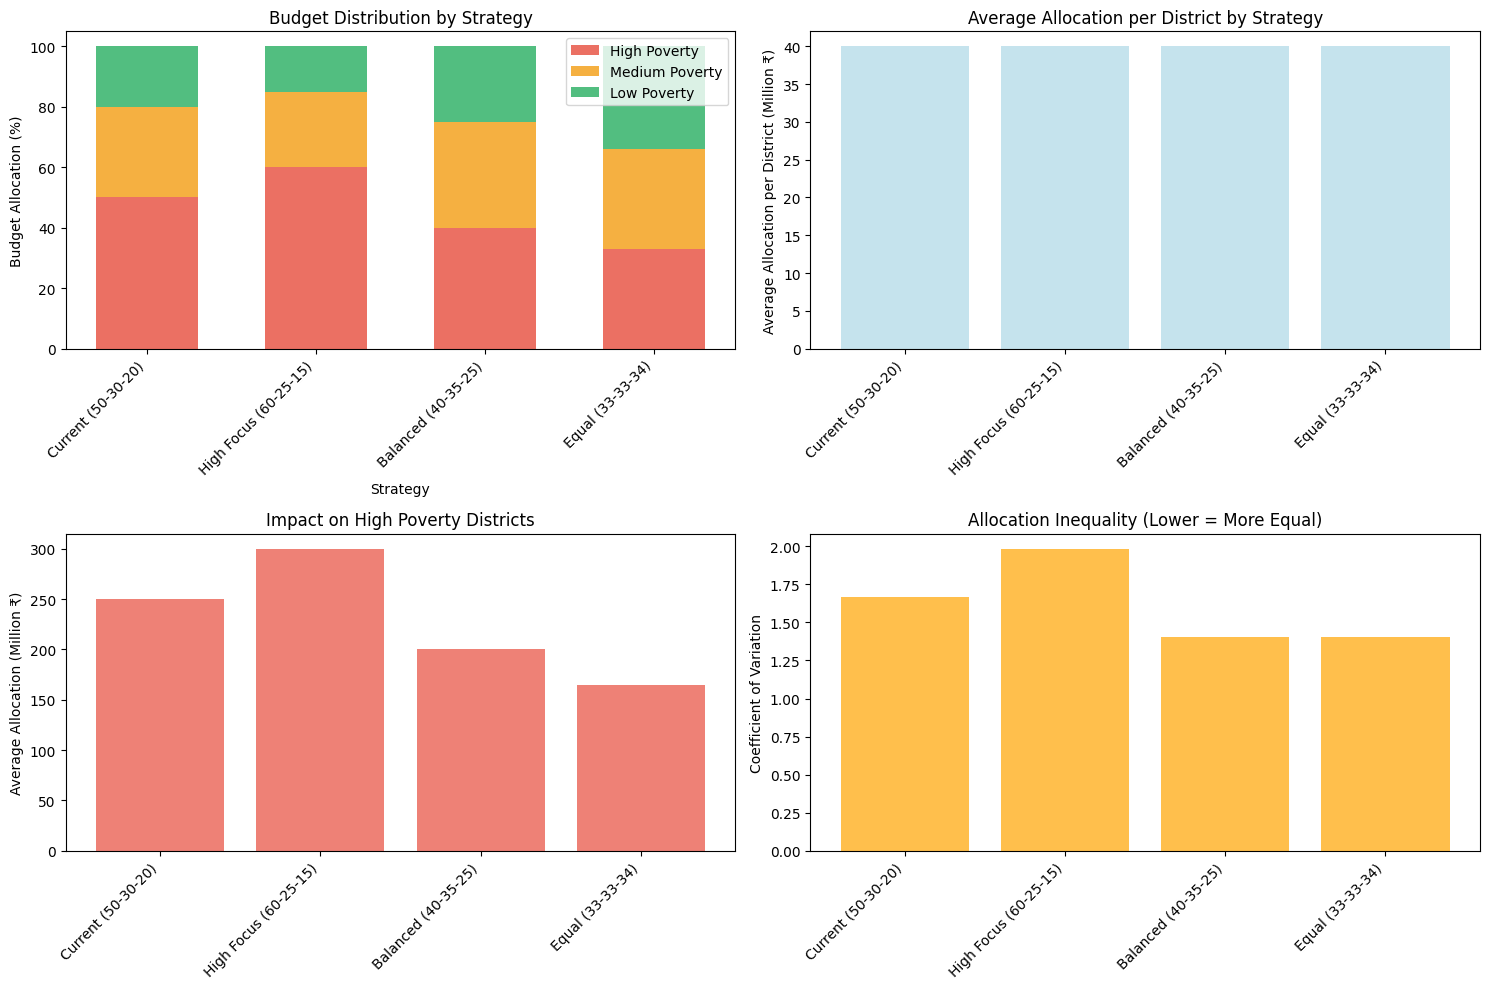


🎯 Strategy Recommendations:
📈 High Focus (60-25-15): Maximizes resources for most needy areas
⚖️ Balanced (40-35-25): Provides more support to medium poverty areas
🤝 Equal (33-33-34): Distributes resources more evenly across all levels

💡 Choose strategy based on policy priorities and available resources


In [20]:
# Visualize strategy comparison
plt.figure(figsize=(15, 10))

# Strategy comparison - budget distribution
plt.subplot(2, 2, 1)
strategy_names = list(strategies.keys())
high_allocations = [strategies[name]['High'] * 100 for name in strategy_names]
medium_allocations = [strategies[name]['Medium'] * 100 for name in strategy_names]
low_allocations = [strategies[name]['Low'] * 100 for name in strategy_names]

x = np.arange(len(strategy_names))
width = 0.6

plt.bar(x, high_allocations, width, label='High Poverty', color='#e74c3c', alpha=0.8)
plt.bar(x, medium_allocations, width, bottom=high_allocations, label='Medium Poverty', color='#f39c12', alpha=0.8)
plt.bar(x, low_allocations, width, bottom=np.array(high_allocations) + np.array(medium_allocations), 
        label='Low Poverty', color='#27ae60', alpha=0.8)

plt.xlabel('Strategy')
plt.ylabel('Budget Allocation (%)')
plt.title('Budget Distribution by Strategy')
plt.xticks(x, strategy_names, rotation=45, ha='right')
plt.legend()

# Average allocation per district by strategy
plt.subplot(2, 2, 2)
avg_allocations_by_strategy = []
for strategy_name in strategy_names:
    summary = strategy_results[strategy_name]['summary']
    avg_allocations_by_strategy.append(summary['average_allocation'] / 1e6)

plt.bar(range(len(strategy_names)), avg_allocations_by_strategy, color='lightblue', alpha=0.7)
plt.xticks(range(len(strategy_names)), strategy_names, rotation=45, ha='right')
plt.ylabel('Average Allocation per District (Million ₹)')
plt.title('Average Allocation per District by Strategy')

# Impact on high poverty districts
plt.subplot(2, 2, 3)
high_poverty_allocations = []
for strategy_name in strategy_names:
    summary = strategy_results[strategy_name]['summary']
    if 'High' in summary['allocation_by_poverty_level']:
        high_avg = summary['allocation_by_poverty_level']['High']['average_allocation'] / 1e6
        high_poverty_allocations.append(high_avg)
    else:
        high_poverty_allocations.append(0)

plt.bar(range(len(strategy_names)), high_poverty_allocations, color='#e74c3c', alpha=0.7)
plt.xticks(range(len(strategy_names)), strategy_names, rotation=45, ha='right')
plt.ylabel('Average Allocation (Million ₹)')
plt.title('Impact on High Poverty Districts')

# Allocation inequality (coefficient of variation)
plt.subplot(2, 2, 4)
inequality_metrics = []
for strategy_name in strategy_names:
    allocation_df = strategy_results[strategy_name]['allocation_df']
    cv = allocation_df['Allocated_Amount'].std() / allocation_df['Allocated_Amount'].mean()
    inequality_metrics.append(cv)

plt.bar(range(len(strategy_names)), inequality_metrics, color='orange', alpha=0.7)
plt.xticks(range(len(strategy_names)), strategy_names, rotation=45, ha='right')
plt.ylabel('Coefficient of Variation')
plt.title('Allocation Inequality (Lower = More Equal)')

plt.tight_layout()
plt.show()

# Print strategy recommendations
print("\n🎯 Strategy Recommendations:")
print("="*40)
print("📈 High Focus (60-25-15): Maximizes resources for most needy areas")
print("⚖️ Balanced (40-35-25): Provides more support to medium poverty areas")
print("🤝 Equal (33-33-34): Distributes resources more evenly across all levels")
print("\n💡 Choose strategy based on policy priorities and available resources")

## 7. Summary and Key Insights

Let's summarize the key findings and insights from our analysis.

In [21]:
# Generate comprehensive summary
print("📋 POVERTY-AWARE RESOURCE ALLOCATION MODEL")
print("="*60)
print(f"📊 Analysis Date: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"🏘️ Districts Analyzed: {len(enhanced_data)}")
print(f"📈 Features Used: {len(X_train.columns) if 'X_train' in locals() else 'N/A'}")
print(f"💰 Total Budget Analyzed: ₹{total_budget:,.0f}")

print("\n🎯 KEY FINDINGS:")
print("-"*20)

# Poverty distribution
poverty_dist = enhanced_data['Poverty_Level'].value_counts()
for level, count in poverty_dist.items():
    pct = (count / len(enhanced_data)) * 100
    print(f"   {level} Poverty: {count} districts ({pct:.1f}%)")

print("\n📊 MODEL PERFORMANCE:")
print("-"*25)
if sklearn_available:
    print(f"   Test Accuracy: {accuracy:.1%}")
    print(f"   Cross-validation: {cv_scores.mean():.1%} ± {cv_scores.std():.1%}")
    print(f"   Average Confidence: {confidence_scores.mean():.1%}")
else:
    print("   Model training skipped (sklearn not available)")

print("\n💰 RESOURCE ALLOCATION INSIGHTS:")
print("-"*35)
allocation_summary = allocator.generate_allocation_summary()
print(f"   Average per district: ₹{allocation_summary['average_allocation']:,.0f}")
print(f"   Allocation range: ₹{allocation_summary['allocation_distribution']['min']:,.0f} - ₹{allocation_summary['allocation_distribution']['max']:,.0f}")

for level, data in allocation_summary['allocation_by_poverty_level'].items():
    print(f"   {level} poverty districts: ₹{data['average_allocation']:,.0f} average ({data['percentage_of_budget']:.1f}% of budget)")

print("\n🔍 TOP PREDICTIVE FACTORS:")
print("-"*30)
if sklearn_available and 'feature_importance' in locals():
    for i, (_, row) in enumerate(feature_importance.head(5).iterrows()):
        print(f"   {i+1}. {row['feature']}: {row['importance']:.3f}")
else:
    # Show correlation-based importance
    numerical_cols = ['Literacy_Rate', 'Employment_Rate', 'Clean_Water_Access', 
                     'Healthcare_Index', 'Education_Index']
    if 'Poverty_Score' in enhanced_data.columns:
        corr_importance = enhanced_data[numerical_cols].corrwith(enhanced_data['Poverty_Score']).abs().sort_values(ascending=False)
        for i, (feature, corr) in enumerate(corr_importance.head(5).items()):
            print(f"   {i+1}. {feature}: {corr:.3f} correlation")

print("\n🚀 RECOMMENDATIONS:")
print("-"*20)
print("   1. 🎯 Focus on literacy improvement programs in high-poverty areas")
print("   2. 💼 Invest in employment generation and skill development")
print("   3. 🏥 Strengthen healthcare infrastructure in underserved regions")
print("   4. 💧 Prioritize access to clean water and sanitation")
print("   5. 📊 Use model predictions to guide policy decisions")
print("   6. 🔄 Regular model updates with new data for better accuracy")

print("\n📈 NEXT STEPS:")
print("-"*15)
print("   • Validate predictions with ground truth data")
print("   • Implement monitoring system for allocation impact")
print("   • Collect feedback from field implementations")
print("   • Expand model to include additional socio-economic factors")
print("   • Develop real-time dashboard for policy makers")

print("\n" + "="*60)
print("✅ Analysis completed successfully!")
print("📊 Use findings to guide poverty alleviation strategies")

📋 POVERTY-AWARE RESOURCE ALLOCATION MODEL
📊 Analysis Date: 2025-08-03 23:39:30
🏘️ Districts Analyzed: 50
📈 Features Used: 20
💰 Total Budget Analyzed: ₹2,000,000,000

🎯 KEY FINDINGS:
--------------------
   Medium Poverty: 42 districts (84.0%)
   Low Poverty: 4 districts (8.0%)
   High Poverty: 4 districts (8.0%)

📊 MODEL PERFORMANCE:
-------------------------
   Test Accuracy: 100.0%
   Cross-validation: 95.0% ± 6.1%
   Average Confidence: 79.4%

💰 RESOURCE ALLOCATION INSIGHTS:
-----------------------------------
   Average per district: ₹40,000,000
   Allocation range: ₹15,714,286 - ₹170,000,000
   High poverty districts: ₹165,000,000 average (33.0% of budget)
   Medium poverty districts: ₹15,714,286 average (33.0% of budget)
   Low poverty districts: ₹170,000,000 average (34.0% of budget)

🔍 TOP PREDICTIVE FACTORS:
------------------------------
   1. Infrastructure_Score: 0.113
   2. Clean_Water_Access: 0.103
   3. Education_Index: 0.093
   4. Development_Index: 0.079
   5. Healthca

## 8. Export Results and Save Analysis

Finally, let's save our analysis results for future use.

In [22]:
# Save analysis results
print("💾 Saving analysis results...")

# Create output directory
output_dir = "notebook_output"
os.makedirs(output_dir, exist_ok=True)

# Save datasets
enhanced_data.to_csv(f"{output_dir}/enhanced_district_data.csv", index=False)
print(f"✅ Enhanced dataset saved: {output_dir}/enhanced_district_data.csv")

if 'allocation_results' in locals():
    allocation_results.to_csv(f"{output_dir}/resource_allocation_results.csv", index=False)
    print(f"✅ Allocation results saved: {output_dir}/resource_allocation_results.csv")

# Save model (if available)
if sklearn_available:
    import joblib
    joblib.dump(rf_model, f"{output_dir}/random_forest_model.pkl")
    print(f"✅ Model saved: {output_dir}/random_forest_model.pkl")
    
    # Save feature importance
    if 'feature_importance' in locals():
        feature_importance.to_csv(f"{output_dir}/feature_importance.csv", index=False)
        print(f"✅ Feature importance saved: {output_dir}/feature_importance.csv")

# Save strategy comparison
if 'strategy_results' in locals():
    strategy_summary = pd.DataFrame({
        'Strategy': list(strategies.keys()),
        'High_Poverty_Pct': [strategies[name]['High']*100 for name in strategies.keys()],
        'Medium_Poverty_Pct': [strategies[name]['Medium']*100 for name in strategies.keys()],
        'Low_Poverty_Pct': [strategies[name]['Low']*100 for name in strategies.keys()]
    })
    strategy_summary.to_csv(f"{output_dir}/strategy_comparison.csv", index=False)
    print(f"✅ Strategy comparison saved: {output_dir}/strategy_comparison.csv")

print(f"\n📁 All results saved in: {output_dir}/")
print("\n🎉 Notebook analysis completed successfully!")
print("🚀 Ready for deployment and further analysis")

💾 Saving analysis results...
✅ Enhanced dataset saved: notebook_output/enhanced_district_data.csv
✅ Allocation results saved: notebook_output/resource_allocation_results.csv
✅ Model saved: notebook_output/random_forest_model.pkl
✅ Feature importance saved: notebook_output/feature_importance.csv
✅ Strategy comparison saved: notebook_output/strategy_comparison.csv

📁 All results saved in: notebook_output/

🎉 Notebook analysis completed successfully!
🚀 Ready for deployment and further analysis
